# 01 — The Illusion

Fix the **true** Sharpe ratio of the data-generating process at 0, 0.5 and 1 (annualized),
simulate thousands of daily return paths, and look at what the **realized** Sharpe ratio
and the cumulative PnL actually do.

Two symmetric failures fall out:

1. **False positives** — zero-edge strategies that post a high realized SR by luck.
2. **False negatives** — genuinely profitable strategies that stay underwater for years.

Background: [`docs/literature-overview.md`](../docs/literature-overview.md).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sharpe_illusion import simulation as sim
from sharpe_illusion import metrics, drawdown

PPY = sim.TRADING_DAYS_PER_YEAR
rng = np.random.default_rng(20260702)

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.color": "#e1e0d9", "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, AQUA, RED, MUTED = "#2a78d6", "#1baf7a", "#e34948", "#898781"


## 1. One year of daily data

Realized (annualized) Sharpe over 252 days, 40,000 paths per true SR.

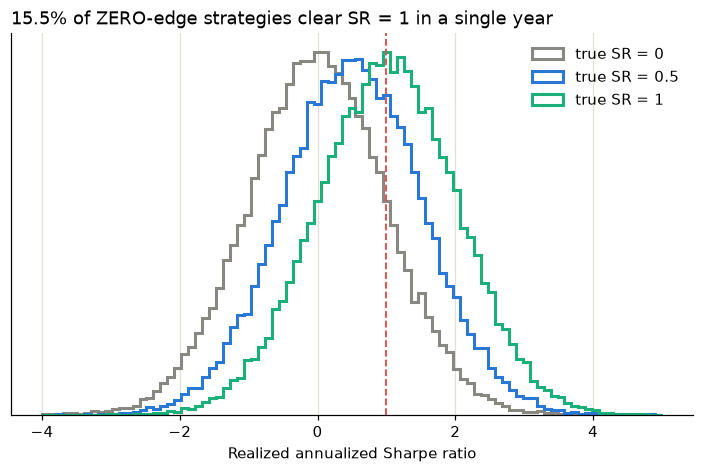

In [2]:
horizon = PPY  # one year
n_paths = 40_000

fig, ax = plt.subplots()
bins = np.linspace(-4, 5, 90)
for sr_true, color in [(0.0, MUTED), (0.5, BLUE), (1.0, AQUA)]:
    srs = sim.realized_sharpe(sim.simulate_returns(sr_true, horizon, n_paths, rng=rng))
    ax.hist(srs, bins=bins, density=True, histtype="step", lw=2,
            color=color, label=f"true SR = {sr_true:g}")
    if sr_true == 0.0:
        frac_fp = np.mean(srs > 1.0)
ax.axvline(1.0, color=RED, ls="--", lw=1.2)
ax.legend(frameon=False)
ax.set_xlabel("Realized annualized Sharpe ratio")
ax.set_yticks([])
ax.set_title(f"{frac_fp:.1%} of ZERO-edge strategies clear SR = 1 in a single year",
             loc="left")
plt.show()

The three distributions overlap almost completely: **over one year, the realized SR
carries very little information about the true SR**. The standard deviation of the
one-year realized SR is roughly 1.0 — the same order as the quantity being measured.

## 2. The mirror image: a good strategy underwater for years

Same experiment from the PnL side. True SR = 0.5 — a strategy most allocators would
happily fund — over 10 years.

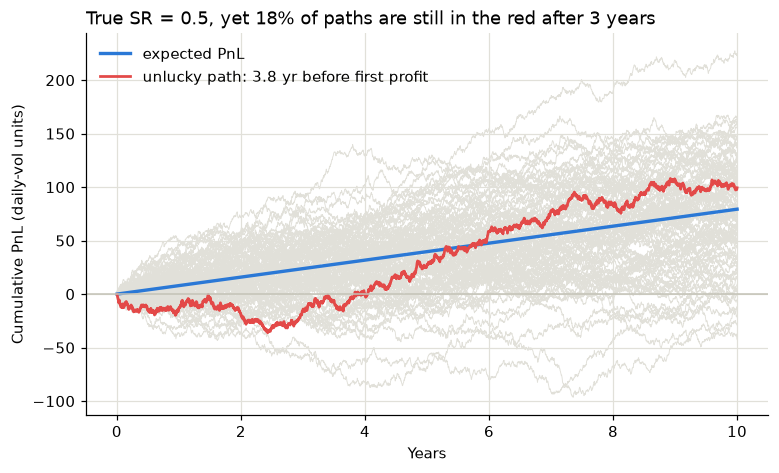

In [3]:
years = 10
horizon = PPY * years
r = sim.simulate_returns(0.5, horizon, 4000, rng=rng)
pnl = sim.cumulative_pnl(r)
t = np.arange(1, horizon + 1) / PPY

# how long does each path take to get (and stay) above water at first?
first_positive = np.where(pnl > 0, True, False).argmax(axis=1) / PPY
frac_red_3y = np.mean(pnl[:, PPY * 3 - 1] < 0)

fig, ax = plt.subplots()
for i in range(100):
    ax.plot(t, pnl[i], color="#e1e0d9", lw=0.6)
drift = 0.5 / np.sqrt(PPY) * np.arange(1, horizon + 1)
ax.plot(t, drift, color=BLUE, lw=2.2, label="expected PnL")
worst = int(np.argmax(first_positive[:500]))
ax.plot(t, pnl[worst], color=RED, lw=1.8,
        label=f"unlucky path: {first_positive[worst]:.1f} yr before first profit")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.legend(frameon=False, loc="upper left")
ax.set_xlabel("Years"); ax.set_ylabel("Cumulative PnL (daily-vol units)")
ax.set_title(f"True SR = 0.5, yet {frac_red_3y:.0%} of paths are still in the red "
             "after 3 years", loc="left")
plt.show()

## 3. Is that drawdown *normal*? The Bouchaud question

Rej, Seager & Bouchaud (2017) ask it the useful way around: **assuming** the strategy
works (true SR fixed), how deep a maximum drawdown should you *expect*? We compare the
closed form (Magdon-Ismail et al. 2004) with the simulated distribution.

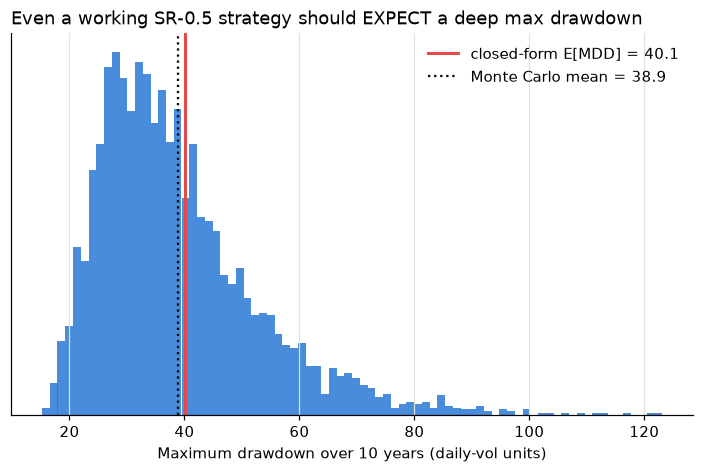

Expected max drawdown ~ 2.5x the annualized volatility
Time underwater (mean fraction of days below prior peak): 95%


In [4]:
mdd = -drawdown.max_drawdown(pnl)          # positive depths, 10y horizon
theory = drawdown.expected_max_drawdown(0.5, horizon)

fig, ax = plt.subplots()
ax.hist(mdd, bins=80, density=True, color=BLUE, alpha=0.85)
ax.axvline(theory, color=RED, lw=2,
           label=f"closed-form E[MDD] = {theory:.1f}")
ax.axvline(np.mean(mdd), color="#0b0b0b", lw=1.5, ls=":",
           label=f"Monte Carlo mean = {np.mean(mdd):.1f}")
ax.legend(frameon=False)
ax.set_xlabel("Maximum drawdown over 10 years (daily-vol units)")
ax.set_yticks([])
ax.set_title("Even a working SR-0.5 strategy should EXPECT a deep max drawdown",
             loc="left")
plt.show()

ann_vol = np.sqrt(PPY)   # annualized vol in daily-vol units
print(f"Expected max drawdown ~ {theory/ann_vol:.1f}x the annualized volatility")
print(f"Time underwater (mean fraction of days below prior peak): "
      f"{np.mean(drawdown.time_underwater_fraction(pnl)):.0%}")

**Takeaway.** With a true SR of 0.5, a maximum drawdown of ~2× the annualized
volatility and spending most days below a prior peak are *the expected behavior of a
working strategy* — not evidence of failure. Both illusions are one fact: the
signal-to-noise of a track record is `t = SR·√T`, and √T grows slowly.

Next: [02_estimation_error](02_estimation_error.ipynb) quantifies exactly how slowly.